# CS2: did practice move skill, and did rank follow?

**Question.** A deliberate training program started on 2026-08-13. Did mechanical skill and kill
output improve after it, and did FACEIT ELO follow?

**Data.** Three sources, built into `data/processed/` by `build.py`:

| table | grain | source |
|---|---|---|
| `faceit_matches.csv` | one FACEIT match | FACEIT Data API v4 (kills, ADR) + stats history (per-match ELO) |
| `matches.csv` | one Leetify match | union of daily Leetify snapshots (aim mechanics), FACEIT kills joined on finish time |
| `profile_stats.csv` | one daily snapshot | Leetify aggregate stats over its rolling 100-match window |

Every number below is reproducible: `python3 build.py`, then run this notebook top to bottom.

In [1]:
from pathlib import Path
import duckdb
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
P = ROOT / "data" / "processed"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

faceit = pd.read_csv(P / "faceit_matches.csv", parse_dates=["finished_at"])
leetify = pd.read_csv(P / "matches.csv", parse_dates=["finished_at"])
profile = pd.read_csv(P / "profile_stats.csv", parse_dates=["captured_at"])

PROGRAM_START = pd.Timestamp("2026-08-13", tz="UTC")
LEVEL_8 = 1531          # FACEIT level 8 floor -- confirm in-client, FACEIT has moved these before

# Chart style: one recessive frame, one series color, text in ink not series color.
SURFACE, INK, MUTED, GRID, SERIES = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df", "#2a78d6"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.titlelocation": "left",
})
print(len(faceit), "FACEIT matches;", len(leetify), "Leetify matches;", len(profile), "snapshots")

308 FACEIT matches; 207 Leetify matches; 8 snapshots


## 1. Coverage first: what the data can and cannot see

Leetify's public API only ever shows the **last 100 matches**, so its history exists only where a
daily snapshot caught it. The capture job silently failed from 2026-08-15 to 10-11 (cron skips
runs while a Mac sleeps, and macOS blocks background jobs from `~/Documents`), so Leetify's
per-match aim data for **Aug 15-23 is gone for good**. FACEIT history is permanent, so kills and
ELO for those days survive. A gap you report is a limitation; a gap you hide is a wrong answer.

In [2]:
cov = pd.DataFrame({
    "source": ["FACEIT (kills, ELO)", "Leetify (aim mechanics)"],
    "matches": [len(faceit), len(leetify)],
    "first": [faceit.finished_at.min().date(), leetify.finished_at.min().date()],
    "last": [faceit.finished_at.max().date(), leetify.finished_at.max().date()],
})
gap = leetify[(leetify.finished_at > "2026-08-15T03:00Z") & (leetify.finished_at < "2026-08-24")]
lost = faceit[(faceit.finished_at > "2026-08-15T03:00Z") & (faceit.finished_at < "2026-08-24")]
print(cov.to_string(index=False))
print(f"\nAug 15-23: {len(gap)} Leetify matches on disk; FACEIT still has {len(lost)} matches from those days.")
print("Per-match ELO present on", faceit.elo.notna().sum(), "of", len(faceit), "FACEIT matches (the rest are non-ELO queues; never imputed).")

                 source  matches      first       last
    FACEIT (kills, ELO)      308 2024-07-08 2026-10-10
Leetify (aim mechanics)      207 2026-07-02 2026-10-10

Aug 15-23: 0 Leetify matches on disk; FACEIT still has 10 matches from those days.
Per-match ELO present on 288 of 308 FACEIT matches (the rest are non-ELO queues; never imputed).


## 2. Rank: FACEIT ELO per match

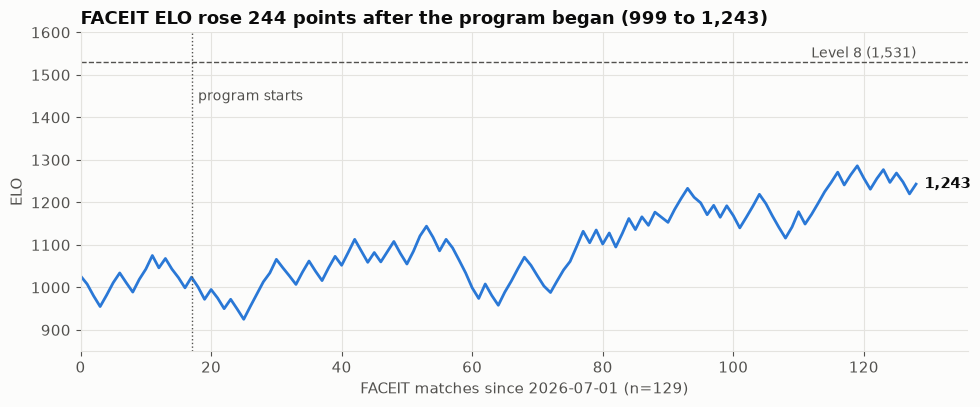

ELO at program start: 999 -> now 1243; peak 1286; 288 to Level 8


In [3]:
elo = faceit.dropna(subset=["elo"])
# x = match number, not date: idle days would otherwise draw as long straight
# lines, and games 40 minutes apart as vertical spikes.
recent = elo[elo.finished_at >= "2026-07-01"].reset_index(drop=True)
start_x = recent.index[recent.finished_at >= PROGRAM_START][0]

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(recent.index, recent.elo, color=SERIES, linewidth=2)
ax.axvline(start_x, color=MUTED, linewidth=1, linestyle=":")
ax.text(start_x + 1, 1440, "program starts", color=MUTED, fontsize=10)
ax.axhline(LEVEL_8, color=MUTED, linewidth=1, linestyle="--")
ax.text(recent.index.max(), LEVEL_8 + 10, "Level 8 (1,531)", color=MUTED, fontsize=10, ha="right")
last = recent.iloc[-1]
ax.annotate(f"{int(last.elo):,}", (recent.index.max(), last.elo), xytext=(6, 0),
            textcoords="offset points", color=INK, va="center", fontweight="bold")
ax.set_ylim(850, 1600)
ax.set_xlim(0, recent.index.max() + 8)
ax.set_title("FACEIT ELO rose 244 points after the program began (999 to 1,243)")
ax.set_ylabel("ELO")
ax.set_xlabel(f"FACEIT matches since 2026-07-01 (n={len(recent)})")
fig.tight_layout(); fig.savefig(FIG / "elo.png", dpi=160); plt.show()

since = elo[elo.finished_at >= PROGRAM_START]
print(f"ELO at program start: {int(elo[elo.finished_at < PROGRAM_START].elo.iloc[-1])} -> now {int(last.elo)}; "
      f"peak {int(since.elo.max())}; {LEVEL_8 - int(last.elo)} to Level 8")

## 3. Did kills follow? Rolling 20-match kills per round

Kills per game depend on how many rounds were played, so the fair measure is **kills per round
(K/R)**. Single matches swing from 0.3 to 1.5, so the line is a rolling 20-match mean.

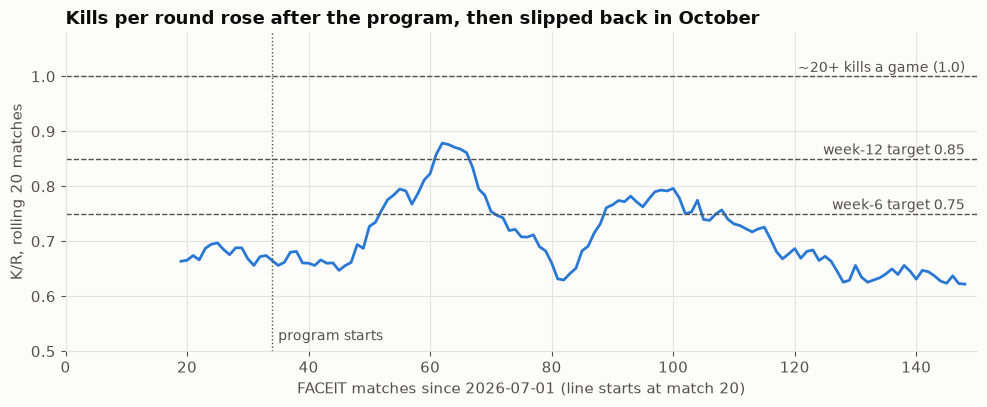

In [4]:
f26 = faceit[faceit.finished_at >= "2026-07-01"].reset_index(drop=True)
f26["kr_roll"] = f26.kr.rolling(20, min_periods=20).mean()
start_x = f26.index[f26.finished_at >= PROGRAM_START][0]

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(f26.index, f26.kr_roll, color=SERIES, linewidth=2)
for y, label in [(0.75, "week-6 target 0.75"), (0.85, "week-12 target 0.85"),
                 (1.0, "~20+ kills a game (1.0)")]:
    ax.axhline(y, color=MUTED, linewidth=1, linestyle="--")
    ax.text(f26.index.max(), y + 0.008, label, color=MUTED, fontsize=10, ha="right")
ax.axvline(start_x, color=MUTED, linewidth=1, linestyle=":")
ax.text(start_x + 1, 0.52, "program starts", color=MUTED, fontsize=10)
ax.set_ylim(0.5, 1.08)
ax.set_xlim(0, f26.index.max() + 2)
ax.set_title("Kills per round rose after the program, then slipped back in October")
ax.set_ylabel("K/R, rolling 20 matches")
ax.set_xlabel("FACEIT matches since 2026-07-01 (line starts at match 20)")
fig.tight_layout(); fig.savefig(FIG / "kills_per_round.png", dpi=160); plt.show()

In [5]:
def ci(s):
    m, se = s.mean(), s.std(ddof=1) / len(s) ** 0.5
    return f"{m:.3f} [{m - 1.96*se:.3f}, {m + 1.96*se:.3f}]"

f = faceit[faceit.finished_at >= "2025-01-01"].copy()
f["period"] = (f.finished_at >= PROGRAM_START).map({False: "before", True: "since program"})
f["win"] = (f.outcome == "win").astype(int)
table = f.groupby("period").agg(
    n=("kr", "size"), kills=("kills", "mean"), kr_95ci=("kr", ci), adr=("adr", "mean"),
    games_20_kills=("kills_20_plus", "mean"), win_rate=("win", "mean")).round(2)
table

,n,kills,kr_95ci,adr,games_20_kills,win_rate
period,,,,,,
before,44,13.70,"0.648 [0.595, 0.700]",75.98,0.09,0.45
since program,115,15.48,"0.708 [0.667, 0.749]",78.75,0.23,0.51


**Reading it honestly.** K/R rose from 0.65 to 0.71, games with 20+ kills went from 9% to
23%, and win rate went from 45% to 51%. But the two 95% intervals overlap, so this is *suggestive,
not proven*. Before the program there are only 44 FACEIT matches since 2025.

In [6]:
wl = faceit[faceit.finished_at >= PROGRAM_START].groupby("outcome")[["kills", "kr", "adr", "deaths"]].mean().round(2)
wl["n"] = faceit[faceit.finished_at >= PROGRAM_START].groupby("outcome").size()
wl

,kills,kr,adr,deaths,n
outcome,,,,,
loss,14.38,0.64,72.53,17.61,56
win,16.53,0.77,84.66,14.81,59


In wins he averages ~2 more kills and ~12 more ADR than in losses. Kills matter, but the
ELO climb did not come from fragging alone: **in October rolling K/R fell to ~0.62 while ELO kept
climbing.** One likely confounder is that Leetify lists one teammate in 56 of the last 100 matches.
A regular duo partner changes win rate independently of individual skill.

## 4. Mechanics (Leetify, per match)

Each mechanic is compared before vs. since the program, with n and a 95% CI. For reaction time
and preaim, **lower is better**.

In [7]:
mech = ["reaction_time_ms", "preaim", "spray_accuracy", "accuracy_head", "accuracy_enemy_spotted"]
leetify["period"] = (leetify.finished_at >= PROGRAM_START).map({False: "before", True: "since program"})
rows = []
for m in mech:
    for period, s in leetify.groupby("period")[m]:
        s = s.dropna()
        mean, se = s.mean(), s.std(ddof=1) / len(s) ** 0.5
        rows.append({"metric": m, "period": period, "n": len(s), "mean": round(mean, 2),
                     "ci_low": round(mean - 1.96*se, 2), "ci_high": round(mean + 1.96*se, 2)})
pd.DataFrame(rows).pivot(index="metric", columns="period", values=["n", "mean", "ci_low", "ci_high"])

n                  mean                ci_low  \
period                 before since program  before since program  before   
metric                                                                      
accuracy_enemy_spotted   96.0         111.0   36.29         34.64   35.29   
accuracy_head            96.0         111.0   18.16         19.97   16.85   
preaim                   96.0         111.0   11.32         10.11   10.66   
reaction_time_ms         96.0         111.0  694.35        640.57  671.92   
spray_accuracy           96.0         111.0   37.94         36.38   36.14   

                                     ci_high                
period                 since program  before since program  
metric                                                      
accuracy_enemy_spotted         33.65   37.29         35.63  
accuracy_head                  18.81   19.46         21.14  
preaim                          9.58   11.98         10.63  
reaction_time_ms              622.27  716.78        658.87  
spray_accuracy                 34.70   39.73         38.06

**Reaction time (694 → 641 ms) and preaim (11.3° → 10.1°) improved with non-overlapping 95%
intervals.** That is a real change, not noise. Headshot accuracy rose slightly but the intervals
overlap. Accuracy when an enemy is spotted *fell* (36.3% → 34.6%), and spray accuracy slipped
(overlapping intervals). Faster reactions have not yet turned into more hits per fight.

## 5. The weaknesses: game-sense stats, August vs. October

These are Leetify's aggregate stats, each averaged over the 100 matches before the snapshot. The
two snapshots share no matches, so this is a clean before/after on independent windows.

In [8]:
first, last = profile.iloc[0], profile.iloc[-1]
LOWER_IS_BETTER = {"flashbang_hit_friend_per_flashbang", "utility_on_death_avg",
                   "he_friends_damage_avg", "preaim", "reaction_time_ms"}
cols = [c for c in profile.columns if c not in
        {"captured_at", "snapshot", "window_start", "window_end", "window_matches",
         "total_matches", "faceit_elo"}]
w = pd.DataFrame({"august": first[cols], "october": last[cols]}).dropna()
w["change"] = w.october.astype(float) - w.august.astype(float)
w["better"] = [((ch < 0) if k in LOWER_IS_BETTER else (ch > 0)) for k, ch in w.change.items()]
print(f"windows: {first.window_start}..{first.window_end}  vs  {last.window_start}..{last.window_end}")
w.round(3).sort_values("better")

windows: 2026-07-02..2026-08-14  vs  2026-08-24..2026-10-10


,august,october,change,better
trade_kills_success_percentage,48.7319,44.3033,-4.429,False
flashbang_hit_friend_per_flashbang,0.4894,0.6237,0.134,False
flashbang_hit_foe_per_flashbang,0.6666,0.6185,-0.048,False
trade_kill_opportunities_per_round,0.2961,0.2961,0.000,False
he_friends_damage_avg,0.1976,0.8739,0.676,False
counter_strafing_good_shots_ratio,87.5355,85.3941,-2.141,False
ct_opening_aggression_success_rate,44.7755,37.0534,-7.722,False
t_opening_duel_success_percentage,41.2922,38.7773,-2.515,False
ct_opening_duel_success_percentage,47.2868,39.7025,-7.584,False
flashbang_leading_to_kill,6.8609,6.2425,-0.618,False


**The rows that got worse are the training plan.** CT opening duels (47% → 40%), flashing
teammates (0.49 → 0.62 per flash, now equal to enemies flashed), utility rating (70 → 61), spray
accuracy (37% → 34%) and trade-kill success (49% → 44%) all declined while raw aim (reaction time,
preaim) improved. T-side opening aggression is the standout gain (35% → 63%). The aim
work paid off. The losses are now in game sense: when to peek, who to flash, being in position to
trade. See `docs/improvement-plan.md`.

## 6. Maps (small samples, labeled as such)

In [9]:
mp = faceit[faceit.finished_at >= PROGRAM_START].assign(win=lambda d: (d.outcome == "win").astype(int))
maps = mp.groupby("map_name").agg(n=("win", "size"), win_rate=("win", "mean"),
                                   kr=("kr", "mean"), adr=("adr", "mean")).round(2)
maps["note"] = ["" if n >= 15 else "n < 15, directional only" for n in maps.n]
maps.sort_values("n", ascending=False)

,n,win_rate,kr,adr,note
map_name,,,,,
de_mirage,31,0.58,0.67,74.55,
de_anubis,17,0.35,0.69,77.71,
de_dust2,16,0.31,0.59,67.71,
de_ancient,15,0.73,0.84,87.65,
de_cache,13,0.46,0.76,82.62,"n < 15, directional only"
de_nuke,11,0.55,0.67,78.40,"n < 15, directional only"
de_inferno,9,0.44,0.77,88.66,"n < 15, directional only"
de_vertigo,3,1.00,0.91,97.33,"n < 15, directional only"


## 7. Limitations and the questions in `sql/`

* **One player, no control group.** Before/after cannot separate practice from teammates, patch
  changes or queue mix. Rising ELO is consistent with the program, not proof of it.
* **The first program was never logged** (`training_log.csv` is empty). The structured blocks from
  2026-10-12 log every session, which makes the independent variable real.
* **Leetify profile stats are 100-match rolling averages**: consecutive daily snapshots share
  ~99% of their matches, so day-to-day changes are not independent observations.
* **Aug 15-23 Leetify gap** (see §1).

Open questions, left as SQL exercises: weak maps with CIs (`03`), whether kills or deaths decide
wins (`04`), whether aim shows up in kills (`05`), the time-of-day confounder (`06`), and the
per-block practice scorecard (`07`).